In [2]:
import os
import matplotlib
from matplotlib import pyplot as plt
%matplotlib inline
import pickle
import pandas as pd
import gzip
import numpy as np
import pandas as pd

def load_compressed_pickle(filepath):
    """Load data from a compressed pickle file."""
    with gzip.open(filepath, 'rb') as f:
        return pickle.load(f)

WFOLD = "./fortnitel1-vmaf"

In [3]:
vmaf_frames = {}
for vmaf in range(50, 96):
  dname = "/tvmaf-%i_tinterval-1/analytix" % vmaf
  vmaf_frames[vmaf] = load_compressed_pickle(WFOLD + dname + "/video_metrics.pkl.gz")

In [4]:
def calc_throughput(df: pd.DataFrame, delta_t: float) -> pd.DataFrame:
    """
    Compute bit-rate in each delta_t interval.
    """
    df = df.sort_values('time')
    max_time = df['time'].max()
    bins = np.arange(0, max_time + delta_t + 1e-8, delta_t)

    df['interval_end'] = pd.cut(
        df['time'],
        bins=bins,
        right=True,
        labels=bins[1:]
    )

    bytes_per_interval = (
        df
        .groupby('interval_end', observed=True)['pkt_size']
        .sum()
        .reindex(bins[1:], fill_value=0)
    )

    bitrates = bytes_per_interval * 8.0 / delta_t

    out = pd.DataFrame({
        'timestamp': np.concatenate(([0.0], bins[1:])),
        'bitrate': np.concatenate(([0.0], bitrates.values))
    })

    return out

In [5]:
delta_t = 1.0  # Time window = 1.0 sec (később 0.1 / 0.5 s -re is csináljam meg)
spatial_complexity_curves = {}
for v in vmaf_frames.keys():
    spatial_complexity_curves[v] = calc_throughput(vmaf_frames[v], delta_t)

spatial_complexity_curves[55].head()

,timestamp,bitrate
0,0.0,0.0
1,1.0,137704.0
2,2.0,156592.0
3,3.0,123472.0
4,4.0,121128.0


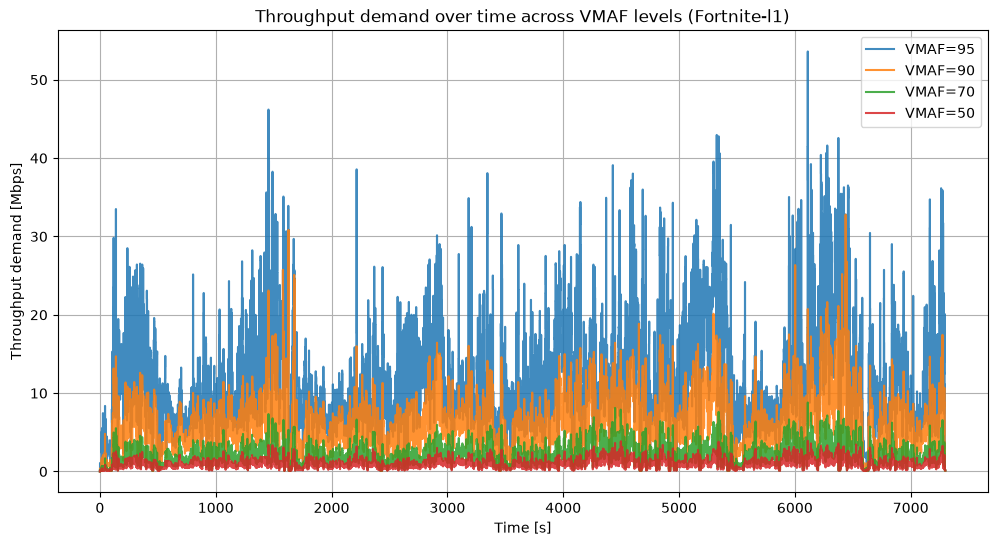

In [6]:
def simple_plot2(
    v, title="", xlabel="Time [s]", ylabel="Throughput demand [Mbps]"
):
  plt.figure(figsize=(12, 6))
  for e in v:
    plt.step(e[0], e[1], label=e[2], alpha=0.85)
  plt.title(title)
  plt.xlabel(xlabel)
  plt.ylabel(ylabel)
  plt.grid(True)
  plt.legend()
  plt.show()


plots = [
    (
        spatial_complexity_curves[95].timestamp.values,
        spatial_complexity_curves[95].bitrate.values / 1e6,
        "VMAF=95",
    ),
    (
        spatial_complexity_curves[90].timestamp.values,
        spatial_complexity_curves[90].bitrate.values / 1e6,
        "VMAF=90",
    ),
    (
        spatial_complexity_curves[70].timestamp.values,
        spatial_complexity_curves[70].bitrate.values / 1e6,
        "VMAF=70",
    ),
    (
        spatial_complexity_curves[50].timestamp.values,
        spatial_complexity_curves[50].bitrate.values / 1e6,
        "VMAF=50",
    ),
]

simple_plot2(
    plots,
    title="Throughput demand over time across VMAF levels (Fortnite-l1)",
    xlabel="Time [s]",
    ylabel="Throughput demand [Mbps]",
)

In [7]:
base_dir = "fortnitel1-crf"
all_data = []

if os.path.exists(base_dir):
    subdirs = [d for d in os.listdir(base_dir) if d.startswith("crf-")]

    for folder in sorted(subdirs):
        try:
            crf_val = int(folder.split("-")[1])
        except ValueError:
            continue

        pkl_file = os.path.join(base_dir, folder, "analytix", "video_metrics.pkl.gz")

        if os.path.exists(pkl_file):
            df = pd.read_pickle(pkl_file, compression="gzip")
            df["crf"] = crf_val
            all_data.append(df)
        else:
            print(f"Hiányzó fájl: {pkl_file}")

    # Összefűzés egyetlen nagy DataFrame-be
    if all_data:
        master_df = pd.concat(all_data, ignore_index=True)
        print("Összefűzött sorok száma:", len(master_df))
        display(master_df.head())
    else:
        print("Egyetlen fájlt sem sikerült betölteni.")
else:
    print("A megadott főmappa nem található.")

Összefűzött sorok száma: 9635934


,time,pkt_size,pict_type,vmaf,crf
0,0.000000,263547,I,95.895896,20
1,0.016667,7342,P,95.504817,20
2,0.033333,1919,P,95.548101,20
3,0.050000,689,P,95.581903,20
4,0.066667,678,P,95.509606,20


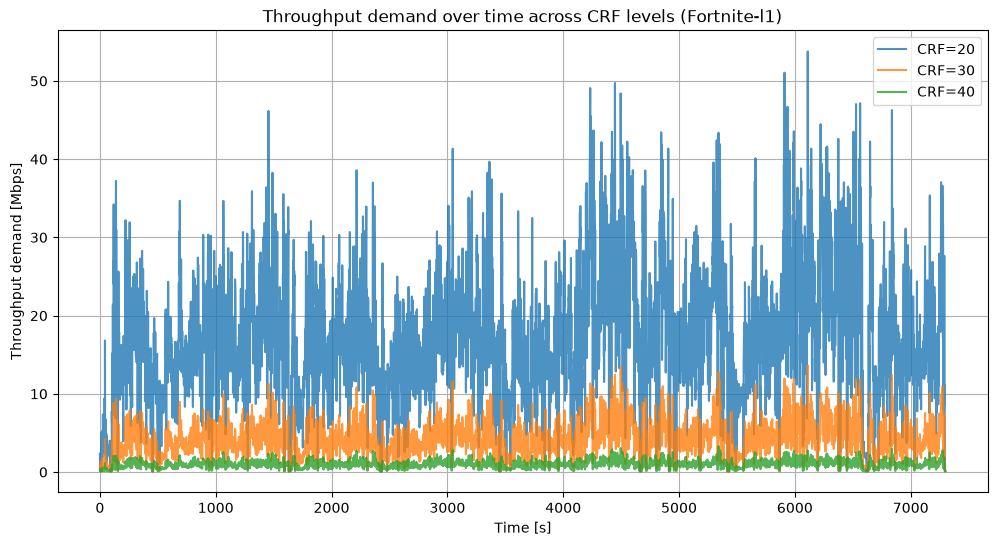

In [8]:
master_df = master_df.sort_values(by="time")

# Csoportosítás időablakok szerint
master_df["time_sec"] = master_df["time"].astype(int)

# Bitráta kiszámítása (Mbps-ben)
throughput_df = (
    master_df.groupby(["crf", "time_sec"])["pkt_size"]
    .sum()
    .reset_index()
)
throughput_df["throughput_mbps"] = (throughput_df["pkt_size"] * 8) / 1_000_000

plt.figure(figsize=(12, 6))
for crf_val in [20, 30, 40]:
    subset = throughput_df[throughput_df["crf"] == crf_val]
    if not subset.empty:
        plt.plot(subset["time_sec"], subset["throughput_mbps"], label=f"CRF={crf_val}", alpha=0.8)

plt.title("Throughput demand over time across CRF levels (Fortnite-l1)")
plt.xlabel("Time [s]")
plt.ylabel("Throughput demand [Mbps]")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
#SCC (Spatial Complexity Curve) generálása a teljes adathalmazra adott időlépésekben, majd mentése
    
def generate_full_scc(df, step=1.0):
  max_time = df["time"].max()
  starts = np.arange(0.0, max_time, step)
  all_scc_rows = []

  for start_t in starts:
    end_t = start_t + step
    window_df = df[(df["time"] >= start_t) & (df["time"] < end_t)]

    if window_df.empty:
      continue

    duration = end_t - start_t

    for crf_val, group in window_df.groupby("crf"):
      total_bits = group["pkt_size"].sum() * 8
      throughput_mbps = total_bits / (duration * 1_000_000)
      avg_vmaf = group["vmaf"].mean() if "vmaf" in group.columns else np.nan

      all_scc_rows.append({
          "start_time": start_t,
          "end_time": end_t,
          "crf": crf_val,
          "throughput_mbps": throughput_mbps,
          "avg_vmaf": avg_vmaf,
      })

  return pd.DataFrame(all_scc_rows)


scc_df = generate_full_scc(master_df, step=1.0)
print("Sorok száma az SCC táblázatban:", len(scc_df))
display(scc_df.head(10))

output_filename = "scc_master_data.pkl"
scc_df.to_pickle(output_filename)
print(f"Sikeresen elmentve: {output_filename}")

Sorok száma az SCC táblázatban: 160600


,start_time,end_time,crf,throughput_mbps,avg_vmaf
0,0.0,1.0,20,2.364088,95.554530
1,0.0,1.0,25,1.459824,93.538885
2,0.0,1.0,26,1.329576,92.979636
3,0.0,1.0,27,1.218056,92.387913
4,0.0,1.0,28,1.110800,91.595979
5,0.0,1.0,29,1.011680,90.838044
6,0.0,1.0,30,0.943832,89.893465
7,0.0,1.0,31,0.861472,88.689923
8,0.0,1.0,32,0.791168,87.487822
9,0.0,1.0,33,0.726336,85.724253


Sikeresen elmentve: scc_master_data.pkl


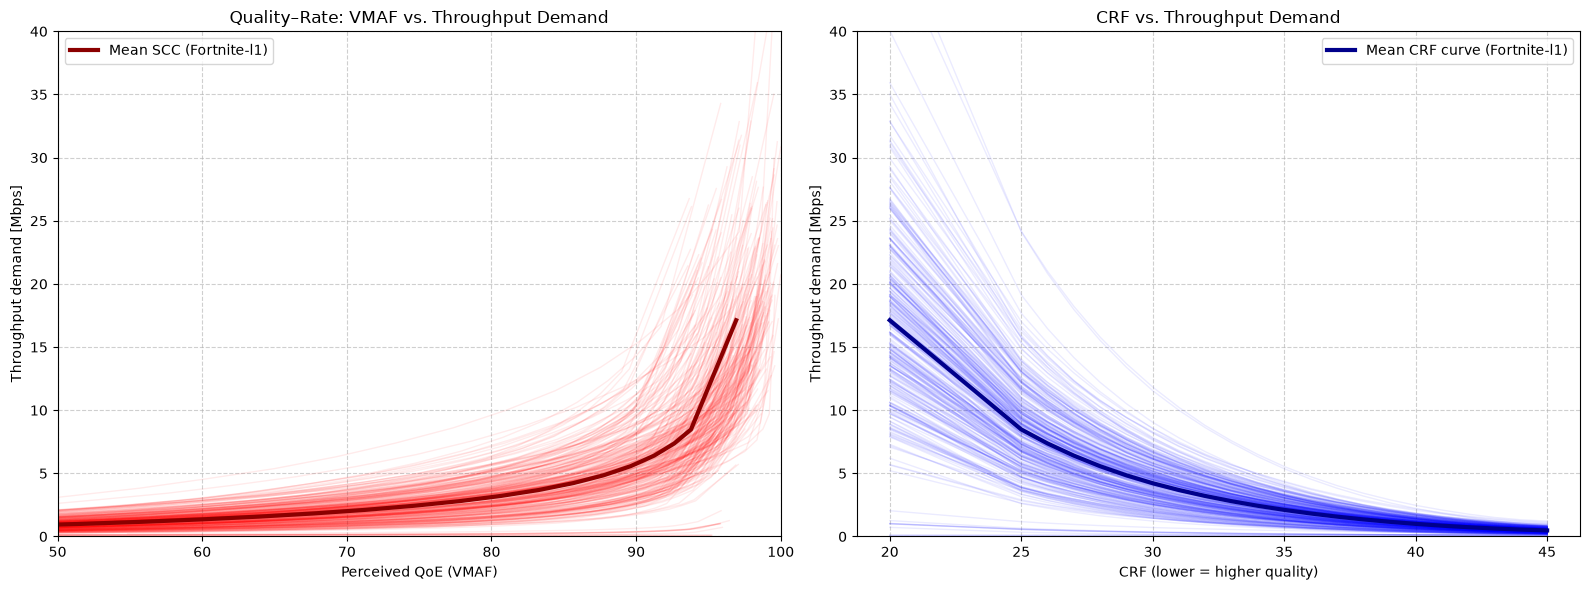

In [10]:
scc_df = pd.read_pickle("scc_master_data.pkl")

rng = np.random.default_rng(42)
unique_times = np.sort(scc_df["start_time"].unique())
sample_size = min(300, len(unique_times))
sample_times = rng.choice(unique_times, size=sample_size, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. panel: Perceived QoE (VMAF) vs. Throughput demand
for t in sample_times:
  window = scc_df[scc_df["start_time"] == t].sort_values(by="avg_vmaf")
  axes[0].plot(
      window["avg_vmaf"],
      window["throughput_mbps"],
      color="red",
      alpha=0.08,
      linewidth=1,
  )

mean_vmaf_curve = (
    scc_df.groupby("crf")[["avg_vmaf", "throughput_mbps"]]
    .mean()
    .sort_values(by="avg_vmaf")
)
axes[0].plot(
    mean_vmaf_curve["avg_vmaf"],
    mean_vmaf_curve["throughput_mbps"],
    color="darkred",
    linewidth=3,
    label="Mean SCC (Fortnite-l1)",
)

axes[0].set_title("Quality–Rate: VMAF vs. Throughput Demand")
axes[0].set_xlabel("Perceived QoE (VMAF)")
axes[0].set_ylabel("Throughput demand [Mbps]")
axes[0].set_xlim(50, 100)
axes[0].set_ylim(0, 40)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

# 2. panel: CRF vs. Throughput Demand
for t in sample_times:
  window = scc_df[scc_df["start_time"] == t].sort_values(by="crf")
  axes[1].plot(
      window["crf"],
      window["throughput_mbps"],
      color="blue",
      alpha=0.08,
      linewidth=1,
  )

mean_crf_curve = (
    scc_df.groupby("crf")["throughput_mbps"]
    .mean()
    .reset_index()
    .sort_values(by="crf")
)
axes[1].plot(
    mean_crf_curve["crf"],
    mean_crf_curve["throughput_mbps"],
    color="darkblue",
    linewidth=3,
    label="Mean CRF curve (Fortnite-l1)",
)

axes[1].set_title("CRF vs. Throughput Demand")
axes[1].set_xlabel("CRF (lower = higher quality)")
axes[1].set_ylabel("Throughput demand [Mbps]")
axes[1].set_ylim(0, 40)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

Eredeti időablakok száma: 7300
Szűrt (aktív játékmenet) időablakok száma: 7075


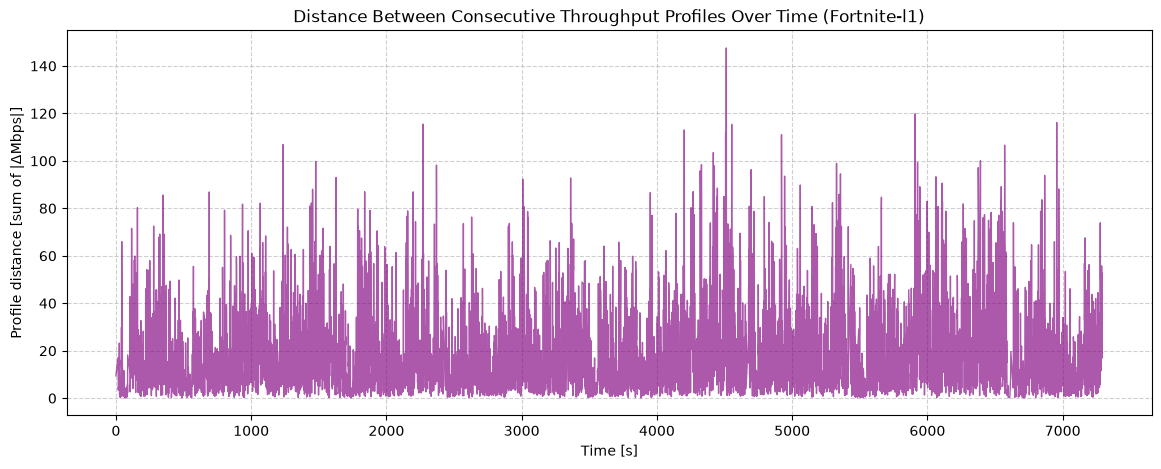

A 10 legnagyobb egymást követő profilváltozás:


,start_time,next_time,curve_distance
4401,4513.0,4514.0,147.559576
4400,4512.0,4513.0,136.504608
5727,5909.0,5910.0,119.815656
6737,6956.0,6957.0,116.169000
2191,2270.0,2271.0,115.501624
4441,4553.0,4554.0,115.405864
4090,4202.0,4203.0,113.024616
4396,4508.0,4509.0,111.924064
4780,4921.0,4925.0,111.045352
1179,1234.0,1235.0,106.909800


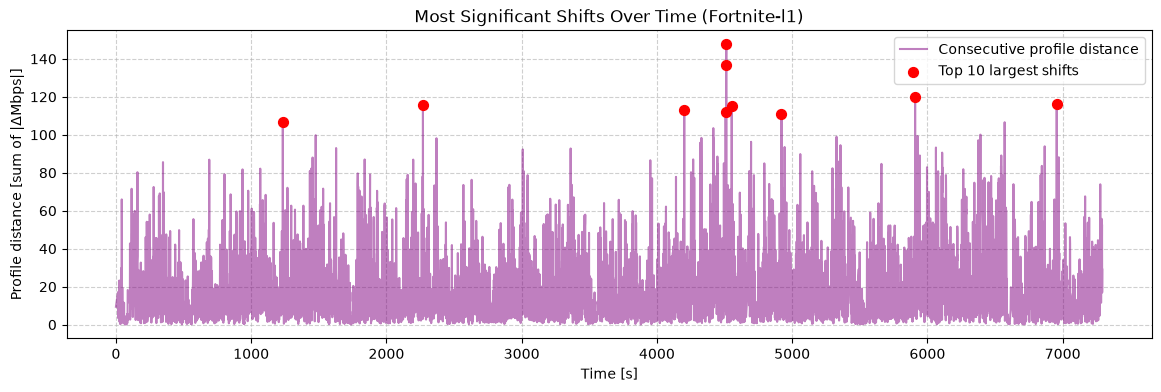

In [11]:
scc_df = pd.read_pickle("scc_master_data.pkl")

# 1. Előszűrés: az elfajult (statikus/menü/nem aktív játékmenet) időablakok kiszűrése, ahol a CRF=20 sávszélessége 2 Mbps alatt van
crf20_df = scc_df[scc_df["crf"] == 20]
valid_times = crf20_df[crf20_df["throughput_mbps"] > 2.0]["start_time"].unique()

filtered_scc_df = scc_df[scc_df["start_time"].isin(valid_times)].copy()

print("Eredeti időablakok száma:", scc_df["start_time"].nunique())
print("Szűrt (aktív játékmenet) időablakok száma:", filtered_scc_df["start_time"].nunique())

# 2. Egymást követő időablakok közötti távolság számítása a CRF-szintek mentén
sorted_times = np.sort(filtered_scc_df["start_time"].unique())
distances = []

for i in range(len(sorted_times) - 1):
    t1 = sorted_times[i]
    t2 = sorted_times[i + 1]

    curve1 = filtered_scc_df[filtered_scc_df["start_time"] == t1].sort_values("crf")
    curve2 = filtered_scc_df[filtered_scc_df["start_time"] == t2].sort_values("crf")

    # Összehasonlítás csak akkor, ha a CRF-struktúra megegyezik a két időszeletben
    if len(curve1) == len(curve2) and np.array_equal(curve1["crf"].values, curve2["crf"].values):
        diff = np.sum(np.abs(curve1["throughput_mbps"].values - curve2["throughput_mbps"].values))
        distances.append({
            "start_time": t1,
            "next_time": t2,
            "curve_distance": diff
        })

dist_df = pd.DataFrame(distances)

# 3. Egymást követő profilok közötti változások idősora
plt.figure(figsize=(14, 5))
plt.plot(dist_df["start_time"], dist_df["curve_distance"], color="purple", alpha=0.65, linewidth=1)
plt.title("Distance Between Consecutive Throughput Profiles Over Time (Fortnite-l1)")
plt.xlabel("Time [s]")
plt.ylabel("Profile distance [sum of |ΔMbps|]")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 4. A 10 legnagyobb váltás kiemelése
top_peaks = dist_df.sort_values(by="curve_distance", ascending=False).head(10)
print("A 10 legnagyobb egymást követő profilváltozás:")
display(top_peaks)

plt.figure(figsize=(14, 4))
plt.plot(dist_df["start_time"], dist_df["curve_distance"], color="purple", alpha=0.5, label="Consecutive profile distance")
plt.scatter(top_peaks["start_time"], top_peaks["curve_distance"], color="red", s=50, zorder=5, label="Top 10 largest shifts")
plt.title("Most Significant Shifts Over Time (Fortnite-l1)")
plt.xlabel("Time [s]")
plt.ylabel("Profile distance [sum of |ΔMbps|]")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

95th percentile |delta curve_distance| (1s steps): 44.55
Large jump count: 351


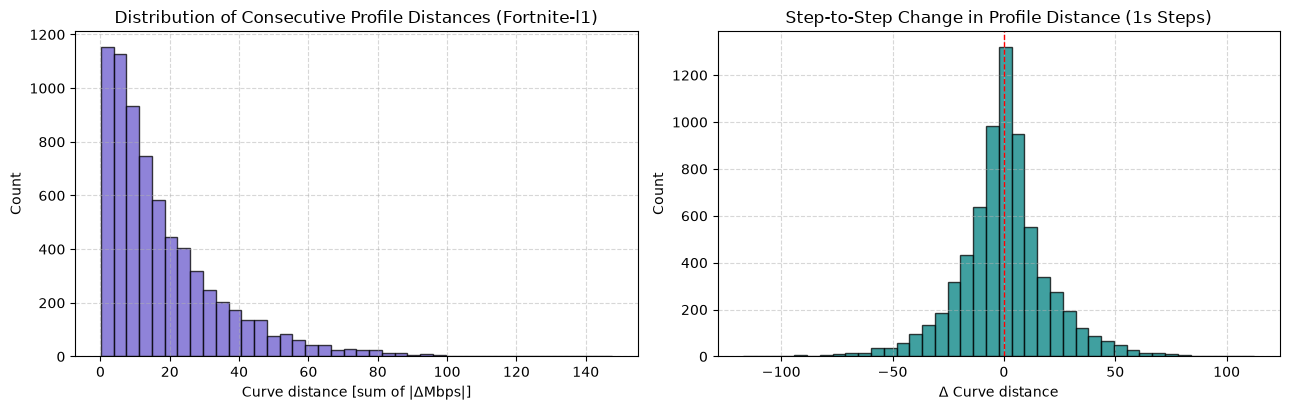

In [ ]:
# 5. Profil-távolságok (curve_distance) és szomszédos különbségek eloszlása
# Cél: megnézni, hogyan oszlanak el az egymást követő SCC-görbék közötti távolságok, valamint mennyit változik maga a profil-távolság egyik másodpercről a következőre.

# Időrendi sorrendbe rendezés, hogy a diff() valóban időben egymást követő sorokat vonjon ki egymásból
d_sorted = dist_df.sort_values("start_time").copy()

# Megnézzük az ablakok közötti időkülönbséget (pl. 1.0 s folytonos-e, vagy volt-e kimaradt/kiszűrt másodperc közte)
d_sorted["dt_step"] = d_sorted["next_time"] - d_sorted["start_time"]

# Lépésenkénti változás a görbetávolságban: pozitív = nőtt a távolság, negatív = csökkent
d_sorted["d_dist"] = d_sorted["curve_distance"].diff()

# A változás abszolút értéke
d_sorted["abs_d_dist"] = d_sorted["d_dist"].abs()

# Csak folytonos (1.0 s) szomszédos lépések a lépésváltozásokhoz és eldobjuk az első sort, ahol még nincs előző lépés
adj_steps = d_sorted[d_sorted["dt_step"] == 1.0].dropna(subset=["abs_d_dist"]).copy()

# Nagy váltás küszöbe: pl. felső 5% a lépésenkénti |delta curve_distance| alapján
jump_thresh = adj_steps["abs_d_dist"].quantile(0.95)

# Logikai eldöntés: True, ha az adott 1s-os lépés eléri vagy meghaladja a nagy váltás küszöbét
adj_steps["is_large_jump"] = adj_steps["abs_d_dist"] >= jump_thresh

print(f"95th percentile |delta curve_distance| (1s steps): {jump_thresh:.2f}")
print(f"Large jump count: {adj_steps['is_large_jump'].sum()}")

# Eloszlásábra: bal oldalon a profil-távolságok, jobb oldalon a lépésváltozások eloszlása
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Bal panel: mekkora profil-távolságok fordulnak elő leggyakrabban a teljes szűrt sorban
axes[0].hist(d_sorted["curve_distance"], bins=40, color="slateblue", edgecolor="black", alpha=0.75)
axes[0].set_title("Distribution of Consecutive Profile Distances (Fortnite-l1)")
axes[0].set_xlabel("Curve distance [sum of |ΔMbps|]")
axes[0].set_ylabel("Count")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Jobb panel: hogyan változik a távolság egyik 1s-os lépésről a következőre (0 körül szimmetrikus-e)
axes[1].hist(adj_steps["d_dist"], bins=40, color="teal", edgecolor="black", alpha=0.75)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_title("Step-to-Step Change in Profile Distance (1s Steps)")
axes[1].set_xlabel("Δ Curve distance")
axes[1].set_ylabel("Count")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Pre-shift stability (False = normal step, True = large jump):


curve_distance                 pre_dist_std                  \
                       count    mean  median        count    mean  median   
is_large_jump                                                               
False                   6666  16.748  12.149         6666  11.147   8.947   
True                     351  43.054  49.987          351  21.643  22.151   

              pre_abs_jump_mean                  
                          count    mean  median  
is_large_jump                                    
False                      6666  14.025  11.397  
True                        351  23.161  21.847

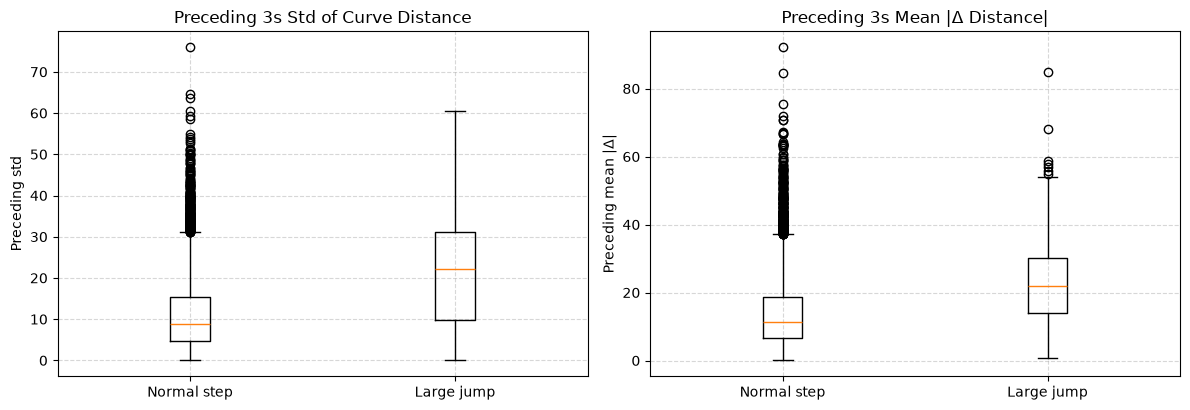

In [ ]:
# 6. Stabilitás és előkép vizsgálata a nagy váltások előtt (megelőző ablak)
# Cél: megnézni, hogy amikor nagy változás történik (is_large_jump == True), azt megelőzően stabilabb volt-e a rendszer, vagy már előtte is magasabb volt az ingadozás (előkép).

lookback_sec = 3  # Hány megelőző másodpercet vizsgálunk az aktuális lépés előtt

# shift(1) eltolja a sorozatot 1 lépéssel, így az aktuális pillanat értéke NEM szivárog bele a saját maga előtti ablakba; 
# rolling(lookback_sec, min_periods=2) pedig kiszámolja az előző max. 3 másodperc szórását (legalább 2 érvényes adatponttal)
adj_steps["pre_dist_std"] = (
    adj_steps["curve_distance"]
    .shift(1)
    .rolling(lookback_sec, min_periods=2)
    .std()
)

# Az előző időablakban az abszolút lépésváltozások (|Δ curve_distance|) átlagát vizsgáljuk meg: mekkora volt a tipikus ugrásméret közvetlenül a nagy váltás előtt
adj_steps["pre_abs_jump_mean"] = (
    adj_steps["abs_d_dist"]
    .shift(1)
    .rolling(lookback_sec, min_periods=2)
    .mean()
)

# Csak azokat a sorokat tartjuk meg az összehasonlításhoz, ahol mindkét előzmény-mutató kiszámolható
pre_df = adj_steps.dropna(subset=["pre_dist_std", "pre_abs_jump_mean"])

# Összesítő statisztikák (esetszám, átlag, medián) normál lépések (False) és nagy ugrások (True) bontásában
summary = pre_df.groupby("is_large_jump")[
    ["curve_distance", "pre_dist_std", "pre_abs_jump_mean"]
].agg(["count", "mean", "median"])
print("Pre-shift stability (False = normal step, True = large jump):")
display(summary.round(3))

# Kétpaneles boxplot összehasonlítás: előzmény szórás és előzmény átlagos abszolút változás
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Bal panel: a nagy váltás előtti görbetávolság-szórás eloszlása (stabilitás mutatója)
axes[0].boxplot(
    [
        pre_df.loc[~pre_df["is_large_jump"], "pre_dist_std"],
        pre_df.loc[pre_df["is_large_jump"], "pre_dist_std"],
    ],
    tick_labels=["Normal step", "Large jump"],
)
axes[0].set_title(f"Preceding {lookback_sec}s Std of Curve Distance")
axes[0].set_ylabel("Preceding std")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Jobb panel: a nagy váltás előtti átlagos |Δ distance| eloszlása (közelgő ugrás előképe)
axes[1].boxplot(
    [
        pre_df.loc[~pre_df["is_large_jump"], "pre_abs_jump_mean"],
        pre_df.loc[pre_df["is_large_jump"], "pre_abs_jump_mean"],
    ],
    tick_labels=["Normal step", "Large jump"],
)
axes[1].set_title(f"Preceding {lookback_sec}s Mean |Δ Distance|")
axes[1].set_ylabel("Preceding mean |Δ|")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()